# Video game sales and reception

**Authors:** Simone Fabio Taurisano and Biagio Chiaranda. This notebook consolidates the five original acquisition, database, integration, quality and visualization notebooks without requiring hidden state between them.

## Research questions and scope
1. How do recorded sales vary with ratings in the available sample?
2. How do release counts and observed ratings change across release years?

The CSV contains title-platform records, not one row per unique game. RAWG user ratings (0-5) and CSV critic scores (typically 0-10) are separate measures. A top-selling post-2010 sample cannot represent all releases since 1980. Marketing expenditure and franchise effects are not observed and cannot be inferred as causal explanations.

## Execution modes
The default run is offline and reproduces analysis of the supplied CSV. No RAWG response cache or MongoDB export was included in the archive. Live enrichment requires a new `RAWG_API_KEY` and `RUN_RAWG=1`. Database persistence additionally requires `MONGODB_URI` and `WRITE_MONGODB=1`. Never reuse the credentials exposed in the original materials.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if p.name == "video_game_market"), None)
if PROJECT is None:
    candidates = [Path.cwd() / "video_game_market", Path.cwd() / "Projects/First_Year_Projects/video_game_market"]
    PROJECT = next((p for p in candidates if p.is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("Start Jupyter in the project directory or its notebooks directory.")
RESULTS = PROJECT / "Data/Results"
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 220, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

import os, re, time, hashlib, unicodedata
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
RUN_RAWG = os.getenv("RUN_RAWG", "0") == "1"
WRITE_MONGODB = os.getenv("WRITE_MONGODB", "0") == "1"
API_KEY = os.getenv("RAWG_API_KEY", "")
MONGODB_URI = os.getenv("MONGODB_URI", "")
CACHE = PROJECT / "Data/RAWG_Cache"
CACHE.mkdir(parents=True, exist_ok=True)


## Acquisition and validation
Retain all raw rows. Invalid dates are explicitly counted. Exact duplicate rows may be removed from the analysis, but distinct platform releases remain distinct. Missing sales are unknown, not zero. The original five-row demonstration is retained as a preview; the enrichment sample contains the top 200 known-sales records released in 2010 or later.

In [2]:
raw = pd.read_csv(PROJECT / "Data/Source/video_game_sales.csv")
required = {"title", "console", "publisher", "release_date", "total_sales", "critic_score", "genre"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing columns: {required - set(raw.columns)}")
games = raw.drop_duplicates().copy()
games["release_date"] = pd.to_datetime(games.release_date, errors="coerce", format="mixed")
games["release_year"] = games.release_date.dt.year
for column in ["total_sales", "critic_score"]:
    games[column] = pd.to_numeric(games[column], errors="coerce")
assert games.total_sales.dropna().ge(0).all()
quality = {"raw_records":len(raw), "exact_duplicate_rows":int(raw.duplicated().sum()), "unique_titles":int(games.title.nunique()), "missing_sales":int(games.total_sales.isna().sum()), "missing_critic_score":int(games.critic_score.isna().sum()), "missing_or_invalid_dates":int(games.release_date.isna().sum())}
(RESULTS / "source_quality.json").write_text(json.dumps(quality,indent=2),encoding="utf-8")
display(pd.Series(quality,name="count").to_frame())
display(games.loc[games.release_year.ge(2015),["title","release_year","total_sales","console"]].head(5))
sample = games.loc[games.release_year.ge(2010) & games.total_sales.notna() & games.title.notna()].sort_values(["total_sales","title","console"],ascending=[False,True,True],kind="stable").head(200).copy()
sample.to_csv(RESULTS / "enrichment_sample.csv",index=False)


,count
raw_records,64016
exact_duplicate_rows,0
unique_titles,39798
missing_sales,45094
missing_critic_score,57338
missing_or_invalid_dates,7051


,title,release_year,total_sales,console
4,Call of Duty: Black Ops 3,2015.0,15.09,PS4
7,Red Dead Redemption 2,2018.0,13.94,PS4
11,Call of Duty: WWII,2017.0,13.40,PS4
15,FIFA 18,2017.0,11.80,PS4
17,FIFA 17,2016.0,10.94,PS4


## Reproducible RAWG enrichment
The original code accepted the first fuzzy search hit. This revision caches full candidate responses, sets request timeouts, retries transient failures and accepts only a unique normalized title match. This conservative match is still not proof of edition/platform equivalence: audit the match table before scientific use. Errors, absent cache entries and ambiguous matches remain distinct states. The source sales record is preserved in every case.

The delay below is an implementation setting, not a claim that a particular API quota is guaranteed. Consult your account terms before enabling a live run.

In [3]:
def normalize_title(value):
    value = unicodedata.normalize("NFKC", str(value)).casefold()
    return re.sub(r"[^\w]+", " ", value).strip()

session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=Retry(total=3,backoff_factor=1,status_forcelist=[429,500,502,503,504],allowed_methods=["GET"],respect_retry_after_header=True)))
if RUN_RAWG and not API_KEY:
    raise ValueError("Set RAWG_API_KEY before enabling live enrichment.")

def fetch_candidates(title):
    cache_path=CACHE / (hashlib.sha256(normalize_title(title).encode()).hexdigest()+".json")
    if cache_path.exists():
        payload=json.loads(cache_path.read_text(encoding="utf-8"))
    elif RUN_RAWG:
        try:
            response=session.get("https://api.rawg.io/api/games",params={"key":API_KEY,"search":title,"page_size":10},timeout=(10,30))
            response.raise_for_status()
            payload=response.json()
            if not isinstance(payload.get("results"),list):
                raise ValueError("Unexpected RAWG response schema")
            cache_path.write_text(json.dumps(payload,ensure_ascii=False,indent=2),encoding="utf-8")
        except (requests.RequestException,ValueError):
            # Do not print request URLs: they contain the API key.
            return None,"request_failed"
        finally:
            time.sleep(1.5)
    else:
        return None,"cache_unavailable"
    exact=[r for r in payload.get("results",[]) if normalize_title(r.get("name",""))==normalize_title(title)]
    return (exact[0],"exact_title_match") if len(exact)==1 else (None,"ambiguous_or_unmatched")

documents=[]
for row in sample.to_dict("records"):
    details,status=fetch_candidates(row["title"])
    identity="|".join([str(row["title"]),str(row["console"]),str(row["release_date"])])
    document={"_id":hashlib.sha256(identity.encode()).hexdigest(),"title":row["title"],
        "csv_data":{"platform":row["console"],"publisher":None if pd.isna(row["publisher"]) else row["publisher"],"sales_global":float(row["total_sales"]),"release_date":row["release_date"].isoformat()},
        "api_data":{"rawg_id":details.get("id") if details else None,"rating":details.get("rating") if details else None,"ratings_count":details.get("ratings_count") if details else None,"playtime":details.get("playtime") if details else None,"genres":[g["name"] for g in details.get("genres",[])] if details else []},
        "integration_status":"full" if details else "partial","match_status":status}
    documents.append(document)
if len({d["_id"] for d in documents}) != len(documents):
    raise ValueError("Conflicting title/platform/date records require manual review before database writes.")
(RESULTS / "integrated_records.json").write_text(json.dumps(documents,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
integrated=pd.json_normalize(documents)
display(integrated.match_status.value_counts().rename_axis("status").to_frame("records"))


,records
status,
cache_unavailable,200


## MongoDB storage and native queries
The document schema preserves platform-level sales and title-level API metadata. Deterministic identifiers make repeated writes idempotent. A connection check uses `ping` rather than inserting test documents. Database operations are optional; offline results remain available in JSON. The original query examples are expressed below through PyMongo, keeping analytical code inside the notebook.

In [4]:
from pymongo import MongoClient, ReplaceOne
query_definitions = {
    "high_user_rating": {"api_data.rating":{"$gt":4.0}},
    "high_rating_and_sales": {"api_data.rating":{"$gte":4.5},"csv_data.sales_global":{"$gte":5.0}},
    "complete_examples": {"integration_status":"full"}
}
genre_pipeline=[{"$match":{"integration_status":"full"}},{"$unwind":"$api_data.genres"},{"$group":{"_id":"$api_data.genres","count":{"$sum":1}}},{"$sort":{"count":-1}}]
platform_pipeline=[{"$group":{"_id":"$csv_data.platform","count":{"$sum":1}}}]
if WRITE_MONGODB:
    if not MONGODB_URI:
        raise ValueError("Set MONGODB_URI before enabling database writes.")
    with MongoClient(MONGODB_URI,serverSelectionTimeoutMS=10000) as client:
        client.admin.command("ping")
        collection=client["GamingDB"]["games_integrated_revised"]
        if documents:
            result=collection.bulk_write([ReplaceOne({"_id":d["_id"]},d,upsert=True) for d in documents],ordered=False)
            print(f"Upserted: {result.upserted_count}; matched: {result.matched_count}")
        for label,query in query_definitions.items():
            print(label,list(collection.find(query,{"_id":0,"title":1,"api_data.rating":1}).limit(5)))
        display(pd.DataFrame(list(collection.aggregate(platform_pipeline))))
        display(pd.DataFrame(list(collection.aggregate(genre_pipeline))))
else:
    print("MongoDB writes and queries skipped: WRITE_MONGODB is disabled.")


MongoDB writes and queries skipped: WRITE_MONGODB is disabled.


## Source coverage and static visualizations
These figures use the supplied CSV and do not reconstruct missing RAWG results. Counts are title-platform records. Critic-score analysis is complete-case and may suffer selection bias because ratings and sales are missing for many releases. Multiple platforms for the same title are correlated observations.

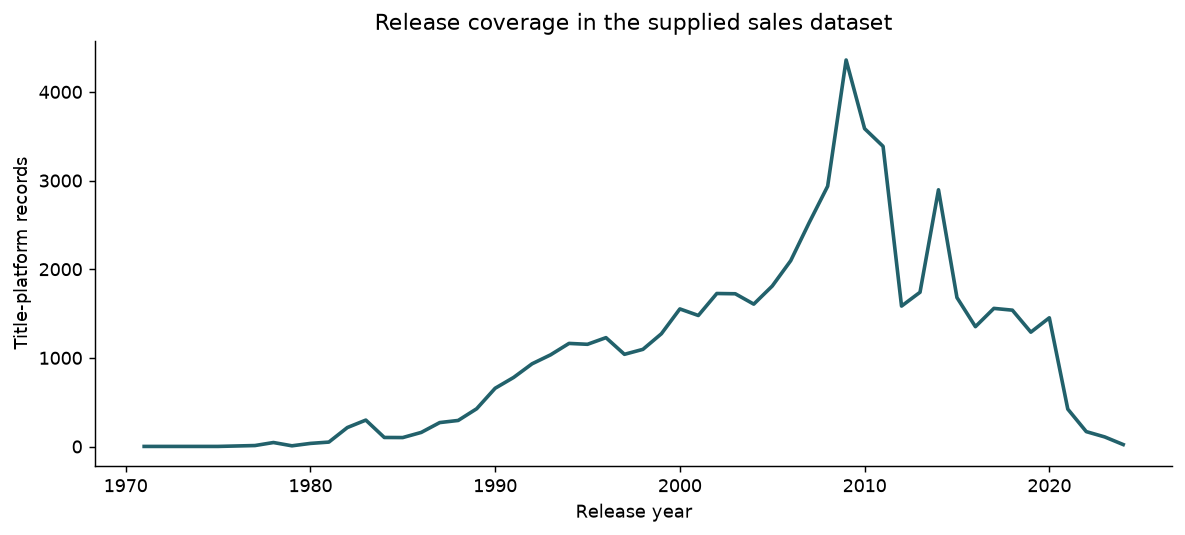

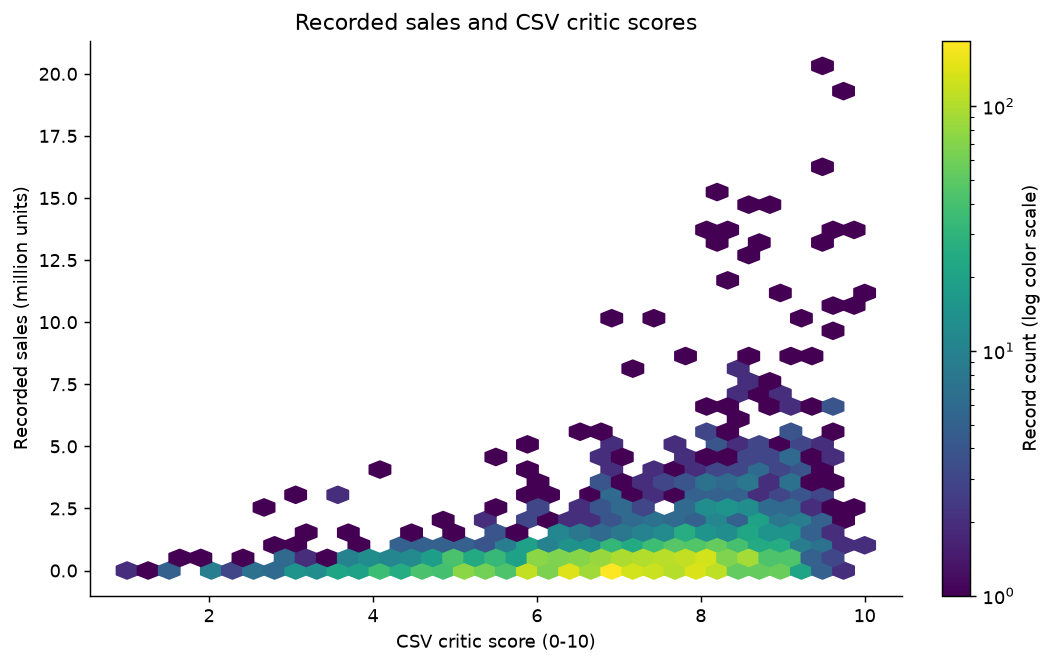

Complete-case records: 4,126; Spearman correlation: 0.338


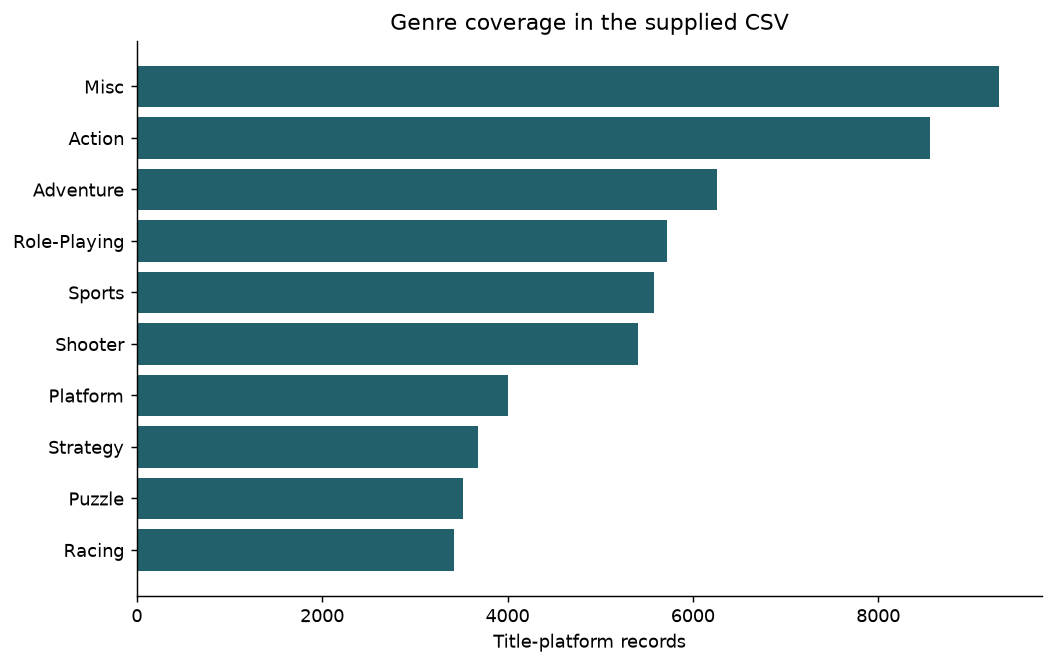

In [5]:
year_counts=games.dropna(subset=["release_year"]).groupby("release_year").size().rename("records")
year_counts.to_csv(RESULTS / "release_counts.csv")
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
ax.plot(year_counts.index,year_counts.values,color="#22616b",lw=2)
ax.set(title="Release coverage in the supplied sales dataset",xlabel="Release year",ylabel="Title-platform records")
fig.savefig(RESULTS / "release_coverage.png",bbox_inches="tight");plt.show()
scored=games.dropna(subset=["total_sales","critic_score"])
fig,ax=plt.subplots(figsize=(8,5),layout="constrained")
hb=ax.hexbin(scored.critic_score,scored.total_sales,gridsize=35,mincnt=1,bins="log",cmap="viridis")
fig.colorbar(hb,ax=ax,label="Record count (log color scale)")
ax.set(title="Recorded sales and CSV critic scores",xlabel="CSV critic score (0-10)",ylabel="Recorded sales (million units)")
fig.savefig(RESULTS / "sales_and_critic_scores.png",bbox_inches="tight");plt.show()
correlation=scored[["critic_score","total_sales"]].corr(method="spearman").iloc[0,1]
(RESULTS / "static_analysis.json").write_text(json.dumps({"complete_case_records":len(scored),"spearman_correlation":float(correlation)},indent=2),encoding="utf-8")
print(f"Complete-case records: {len(scored):,}; Spearman correlation: {correlation:.3f}")
genres=games.genre.fillna("Unknown").value_counts().head(10).sort_values()
fig,ax=plt.subplots(figsize=(8,5),layout="constrained")
ax.barh(genres.index,genres.values,color="#22616b");ax.set(xlabel="Title-platform records",title="Genre coverage in the supplied CSV")
fig.savefig(RESULTS / "source_genre_coverage.png",bbox_inches="tight");plt.show()


## Enriched analysis and quality assessment
Only matched, positively rated records with an available rating count enter the rating analysis. A zero rating is not automatically interpreted as the lowest quality. Completeness is reported against the attempted sample. Repeated titles across platforms are retained for sales but collapsed to distinct RAWG IDs for genre counts and longitudinal user ratings. The yearly rating series uses the earliest sampled release for each RAWG ID and must not be interpreted as a population trend.

In [6]:
full=integrated.loc[integrated.integration_status.eq("full")].copy()
print(f"Enrichment completeness: {len(full)}/{len(integrated)}")
print(f"Repeated sampled titles across platforms: {int(integrated.duplicated('title').sum())}")
if full.empty:
    print("No cached RAWG matches: enriched plots and historical match-rate claims cannot be reproduced.")
else:
    full["year"]=pd.to_datetime(full["csv_data.release_date"]).dt.year
    for c in ["api_data.rating","api_data.ratings_count","csv_data.sales_global"]:
        full[c]=pd.to_numeric(full[c],errors="coerce")
    rated=full.loc[full["api_data.rating"].gt(0) & full["api_data.ratings_count"].gt(0)].dropna(subset=["csv_data.sales_global"])
    fig,ax=plt.subplots(figsize=(8,5),layout="constrained")
    ax.scatter(rated["api_data.rating"],rated["csv_data.sales_global"],alpha=.6,color="#22616b")
    ax.set(xlabel="RAWG user rating (0-5)",ylabel="Platform sales (million units)",title="Sales and user ratings in the enriched sample")
    fig.savefig(RESULTS/"rawg_sales_and_ratings.png",bbox_inches="tight");plt.show()
    unique=rated.sort_values("year").drop_duplicates("api_data.rawg_id")
    annual=unique.groupby("year")["api_data.rating"].agg(["mean","count"])
    annual.to_csv(RESULTS/"rawg_annual_ratings.csv")
    fig,ax=plt.subplots(figsize=(8,4),layout="constrained")
    ax.plot(annual.index,annual["mean"],marker="o",color="#22616b")
    ax.set(xlabel="Earliest sampled release year",ylabel="Mean RAWG user rating",title="User ratings within the selected sample")
    fig.savefig(RESULTS/"rawg_rating_by_year.png",bbox_inches="tight");plt.show()
    genre_counts=full.drop_duplicates("api_data.rawg_id")["api_data.genres"].explode().dropna().value_counts().head(8).sort_values()
    fig,ax=plt.subplots(figsize=(8,4),layout="constrained")
    ax.barh(genre_counts.index,genre_counts.values,color="#22616b");ax.set(xlabel="Distinct matched RAWG games",title="Genre prevalence in the enriched sample")
    fig.savefig(RESULTS/"rawg_genre_coverage.png",bbox_inches="tight");plt.show()


Enrichment completeness: 0/200
Repeated sampled titles across platforms: 73
No cached RAWG matches: enriched plots and historical match-rate claims cannot be reproduced.


## Conclusions
The local CSV supports reproducible coverage and sales/critic-score descriptions. The cloud enrichment architecture is retained, but the original RAWG/MongoDB data are absent from the archive. Consequently, original user-rating plots, integration completeness and database-query counts are historical evidence, not reproduced results. A new live run produces a new time-dependent snapshot and may differ from the original.

Exact title matching reduces one source of error but does not validate edition equivalence. Future work should preserve identifiers, audit uncertain matches, add contemporaneous review timestamps and use a defensible sampling design. NLP sentiment analysis remains proposed work; no such experiment was supplied.